<a href="https://colab.research.google.com/github/HamidBekamiri/BDS-Teaching/blob/main/M2_03_who_matters_centrality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 3 · Who matters? Node-level measures

*M2 Network Analysis · Mapping collaboration with networks*

**The story so far.** Part 2 turned patent records into an inventor network and found its connected core (~200 inventors).

> **Today's question:** Inside the core of the inventor network, who is important — and does 'important' always mean the same thing?

**You will learn to**

1. Compute **degree**, **strength**, **closeness**, **betweenness** and **eigenvector** centrality.
2. Check each measure against the hand calculation on the 7-node graph.
3. Show that different measures pick out *different kinds* of important inventors.
4. Explore paths, neighbourhoods and ego networks.

In [ ]:
# In Google Colab everything below is already installed.
# Locally: pip install networkx pandas matplotlib scipy
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 40)
TEAL, ORANGE, GREY = "#0097A7", "#FFA940", "#B0BEC5"

In [ ]:
def draw(G, pos, node_size=60, node_color=TEAL, labels=False, title=None, ax=None,
         cmap=None, edge_alpha=0.35, width=0.8, font_size=8):
    """One consistent way of drawing a network, used throughout the course."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    arrows = dict(arrows=True, arrowsize=7, node_size=node_size) if G.is_directed() else {}
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=edge_alpha, width=width, edge_color="#78909C", **arrows)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size, node_color=node_color,
                           cmap=cmap, edgecolors="white", linewidths=0.6)
    if labels:
        nx.draw_networkx_labels(G, pos, ax=ax, labels=labels if isinstance(labels, dict) else None,
                                font_size=font_size)
    if title:
        ax.set_title(title, loc="left", fontweight="bold")
    ax.axis("off")
    return ax


def community_colors(G, membership):
    """A distinct colour per community: membership = {node: community number}."""
    return [plt.cm.tab20(membership[n] % 20) for n in G]

**Rebuild the network from Part 2** (same steps, in one cell):

In [ ]:
from networkx.algorithms import bipartite

URL = ("https://raw.githubusercontent.com/hamidb201214-svg/Lectures/"
       "refs/heads/main/data/epo_inventors_clean.csv")
df = pd.read_csv(URL, low_memory=False)                 # the file is UTF-8 (keeps Ø, Å, Æ)
df = df.drop_duplicates(["inv_name", "appln_id"])       # one row per inventor x application

# Two-mode network: inventors <-> applications  (built step by step in Part 2)
B = nx.Graph()
B.add_nodes_from(df["inv_name"].unique(), bipartite="inventor")
B.add_nodes_from(df["appln_id"].unique(), bipartite="application")
B.add_edges_from(df[["inv_name", "appln_id"]].itertuples(index=False, name=None))

def ordered(H):
    """Same node and edge order on every computer, so layouts and communities are reproducible."""
    R = nx.Graph()
    R.add_nodes_from(sorted(H.nodes(data=True)))
    R.add_edges_from(sorted((min(u, v), max(u, v), d) for u, v, d in H.edges(data=True)))
    return R

# One-mode projection: inventor -- inventor, weight = number of shared applications
G = ordered(bipartite.weighted_projected_graph(B, df["inv_name"].unique()))

# The "core": the largest connected group of inventors
core = ordered(G.subgraph(max(nx.connected_components(G), key=len)))
pos = nx.spring_layout(core, seed=7, k=0.25)             # fixed seed = same picture every time

print("Full network:", G)
print("Core        :", core)

Full network: Graph with 3744 nodes and 7632 edges
Core        : Graph with 205 nodes and 814 edges


## 0. Warm-up: check the hand calculations

Before trusting the computer on 200 inventors, check it on the 7-node graph we solved by hand in the lecture.

In [ ]:
# The 7-node graph from the lecture slides (the one we worked through by hand)
toy = nx.Graph([("A", "B"), ("A", "C"), ("A", "D"), ("B", "C"), ("B", "D"),
                ("C", "D"), ("C", "E"), ("D", "E"), ("E", "F"), ("F", "G")])
toy_pos = {"A": (0, 1), "B": (0, -1), "C": (1.3, 1), "D": (1.3, -1),
           "E": (2.6, 0), "F": (3.9, 0), "G": (5.2, 0)}

In [ ]:
check = pd.DataFrame({
    "degree":      dict(toy.degree()),
    "closeness":   nx.closeness_centrality(toy),
    "betweenness": nx.betweenness_centrality(toy),
    "eigenvector": nx.eigenvector_centrality(toy),
    "clustering":  nx.clustering(toy),
}).round(3)
check

,degree,closeness,betweenness,eigenvector,clustering
A,3,0.500,0.000,0.428,1.000
B,3,0.500,0.000,0.428,1.000
C,4,0.667,0.200,0.505,0.667
D,4,0.667,0.200,0.505,0.667
E,3,0.667,0.533,0.333,0.333
F,2,0.500,0.333,0.109,0.000
G,1,0.353,0.000,0.032,0.000


Compare with the slides: **E** has the highest betweenness (8/15 ≈ 0.533) although **C** and **D** have the
highest degree (4). C, D and E tie on closeness (2/3). Eigenvector rewards C and D, who sit in the dense block.
Now let us scale up.

## 1. Degree: how many partners?

$$k_i = \sum_j A_{ij}$$

The simplest idea of importance: the number of distinct co-inventors.

In [ ]:
degree = pd.Series(dict(core.degree()), name="degree")
degree.nlargest(10)

KIILERICH PRATAS, Nuno Manuel    40
SABOURI-SICHANI, Faranaz         39
CAPORAL DEL BARRIO, Samantha     32
LASELVA, Daniela                 31
FREDERIKSEN, Frank               29
ROSA, Claudio                    28
SVENDSEN, Simon                  25
LI, Zexian                       23
VEJLGAARD, Benny                 23
JI, Lianghai                     21
Name: degree, dtype: int64

### Degree vs strength: breadth vs depth
- **Degree** = number of distinct collaborators (*breadth*).
- **Strength** (weighted degree) = total joint applications, summed over partners (*depth*).
- **Strength per partner** = strength ÷ degree: how often, on average, someone repeats a collaboration.

In [ ]:
stats = pd.DataFrame({"degree": degree,
                      "strength": pd.Series(dict(core.degree(weight="weight")))})
stats["per_partner"] = (stats["strength"] / stats["degree"]).round(2)

print("Broad collaborators (most partners):")
display(stats.nlargest(5, "degree"))
# Inside the core nobody with <= 3 partners repeats much, so look at the whole network G for "deep" ties
full = pd.DataFrame({"degree": dict(G.degree()), "strength": dict(G.degree(weight="weight"))})
full["per_partner"] = (full["strength"] / full["degree"]).round(2)
print("Deep collaborators in the whole network (at most 3 partners, many repeats):")
display(full[full["degree"].between(1, 3)].nlargest(5, "per_partner"))

Broad collaborators (most partners):


,degree,strength,per_partner
"KIILERICH PRATAS, Nuno Manuel",40,95,2.38
"SABOURI-SICHANI, Faranaz",39,96,2.46
"CAPORAL DEL BARRIO, Samantha",32,96,3.00
"LASELVA, Daniela",31,59,1.90
"FREDERIKSEN, Frank",29,68,2.34


Deep collaborators in the whole network (at most 3 partners, many repeats):


,degree,strength,per_partner
"Cerda Varela, Alejandro",3,18,6.0
"AHRENFELDT, Jesper",3,12,4.0
"Alberts, Johannes Gerhardes Wardjan",2,8,4.0
"CAVKA, Adnan",1,4,4.0
"ENEMARK, Frode",1,4,4.0


## 2. Closeness: how close to everyone?

$$C_i = \frac{n-1}{\sum_j d(i,j)}$$

The inverse of the average distance to all others. High closeness = information from you reaches everyone quickly.

In [ ]:
closeness = pd.Series(nx.closeness_centrality(core), name="closeness")
closeness.nlargest(5).round(3)

KIILERICH PRATAS, Nuno Manuel    0.481
SABOURI-SICHANI, Faranaz         0.458
CAPORAL DEL BARRIO, Samantha     0.444
FREDERIKSEN, Frank               0.439
LASELVA, Daniela                 0.432
Name: closeness, dtype: float64

## 3. Betweenness: who is the bridge?

$$B_i = \sum_{s \ne i \ne t} \frac{\sigma_{st}(i)}{\sigma_{st}}$$

The share of shortest paths between other pairs that pass through $i$. High betweenness = a **broker** or
**gatekeeper** who connects groups that would otherwise be far apart.

In [ ]:
betweenness = pd.Series(nx.betweenness_centrality(core), name="betweenness")
betweenness.nlargest(5).round(3)

KIILERICH PRATAS, Nuno Manuel    0.209
NIELSEN, Kim                     0.152
SABOURI-SICHANI, Faranaz         0.122
CAPORAL DEL BARRIO, Samantha     0.110
LI, Zexian                       0.071
Name: betweenness, dtype: float64

## 4. Eigenvector: connected to the well-connected

$$x_i = \frac{1}{\lambda} \sum_j A_{ij}\, x_j$$

You are important if your partners are important (the idea behind Google's PageRank).

In [ ]:
eigenvector = pd.Series(nx.eigenvector_centrality(core, max_iter=1000), name="eigenvector")
eigenvector.nlargest(5).round(3)

KIILERICH PRATAS, Nuno Manuel    0.275
SABOURI-SICHANI, Faranaz         0.263
CAPORAL DEL BARRIO, Samantha     0.222
FREDERIKSEN, Frank               0.207
LASELVA, Daniela                 0.195
Name: eigenvector, dtype: float64

## 5. Four measures, four different stories

Put all measures side by side, and draw the core four times with node size = the measure.

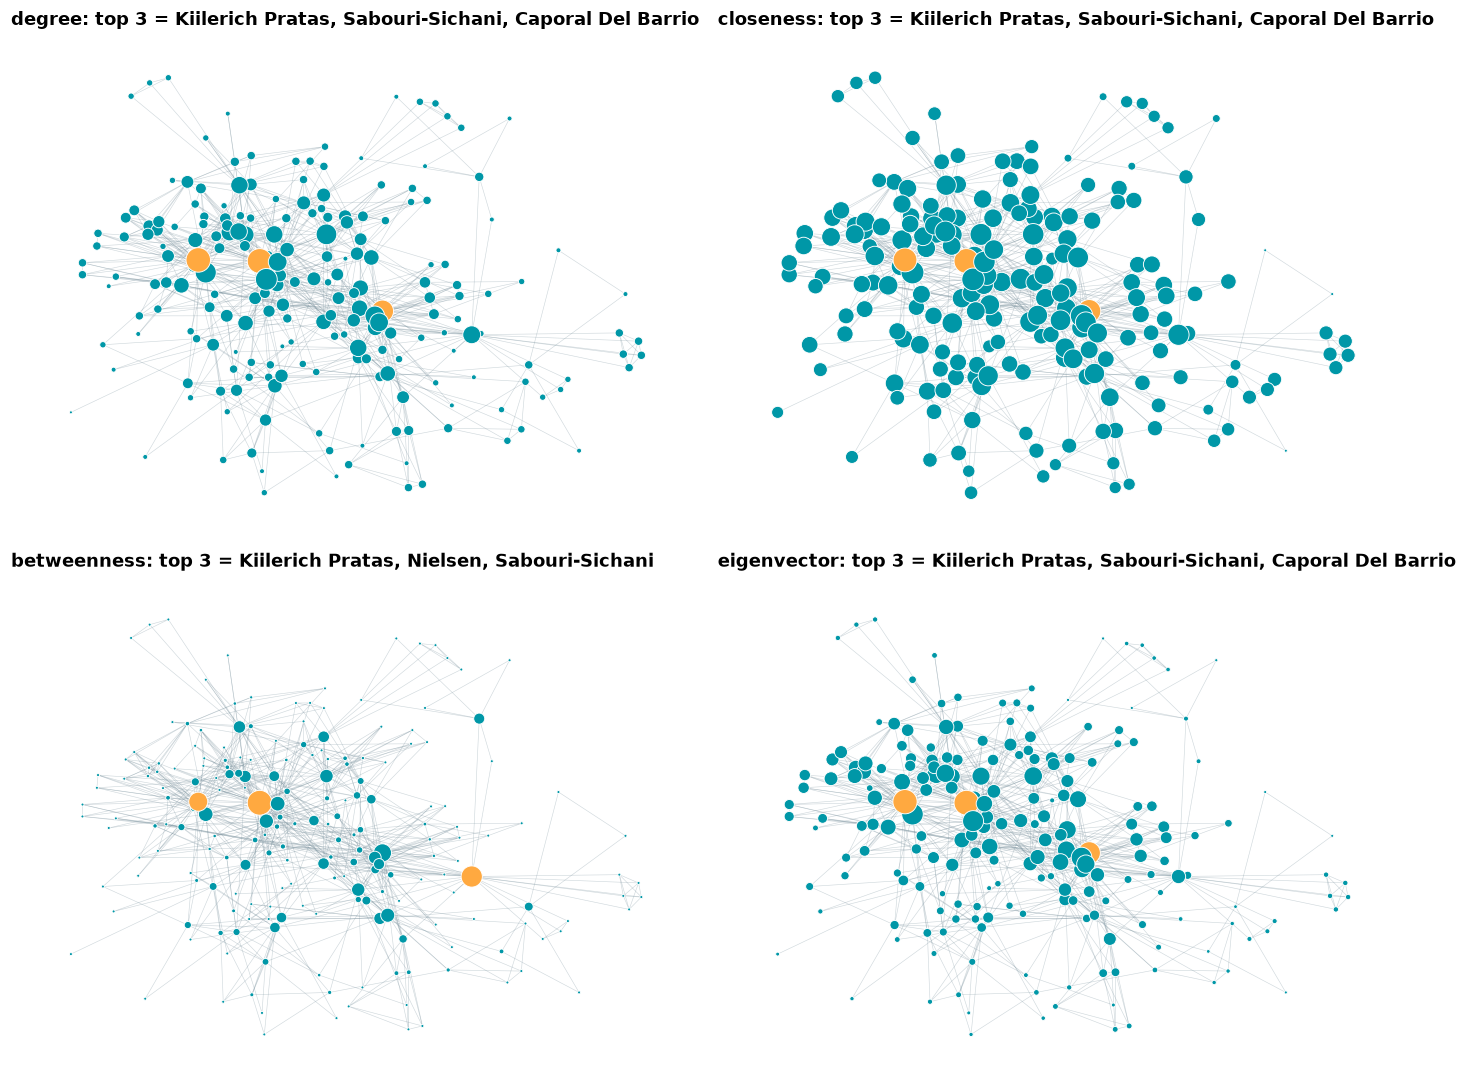

In [ ]:
cent = pd.concat([degree, closeness, betweenness, eigenvector], axis=1)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, col in zip(axes.flat, cent.columns):
    s = (cent[col] - cent[col].min()) / (cent[col].max() - cent[col].min())   # rescale to 0..1
    top3 = cent[col].nlargest(3).index
    draw(core, pos, ax=ax, node_size=[4 + 260 * s[n] for n in core],
         node_color=[ORANGE if n in top3 else TEAL for n in core], width=0.4,
         title=f"{col}: top 3 = " + ", ".join(n.split(",")[0].title() for n in top3))
plt.tight_layout(); plt.show()

In [ ]:
# Do the measures agree? Spearman rank correlation
cent.corr(method="spearman").round(2)

,degree,closeness,betweenness,eigenvector
degree,1.00,0.87,0.85,0.87
closeness,0.87,1.00,0.75,0.94
betweenness,0.85,0.75,1.00,0.68
eigenvector,0.87,0.94,0.68,1.00


All measures agree to some extent (they are positively correlated), but **betweenness agrees least** with the
others — especially with eigenvector. Kim Nielsen, for example, has only 21 partners (half as many as the top inventor) but is 2nd on betweenness.
The plot below shows why: some inventors have few partners but sit on many shortest paths.

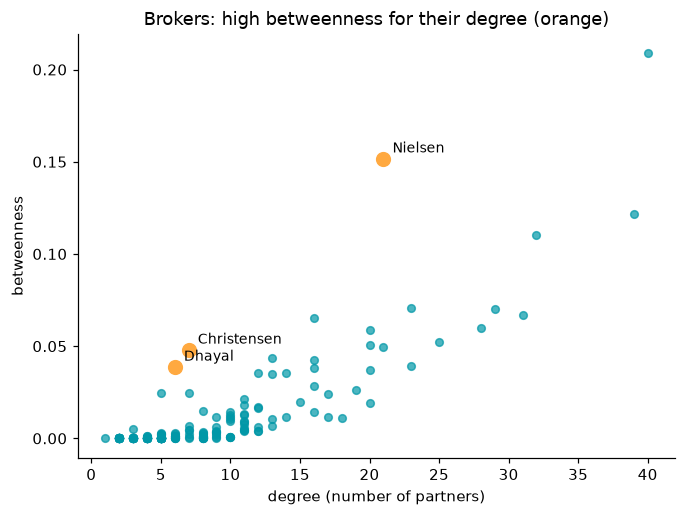

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(cent["degree"], cent["betweenness"], s=25, color=TEAL, alpha=0.7)
brokers = (cent["betweenness"] / cent["betweenness"].max() - cent["degree"] / cent["degree"].max()).nlargest(3).index
for n in brokers:
    ax.scatter(cent.loc[n, "degree"], cent.loc[n, "betweenness"], s=80, color=ORANGE, zorder=3)
    ax.annotate(n.split(",")[0].title(), (cent.loc[n, "degree"], cent.loc[n, "betweenness"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.set(xlabel="degree (number of partners)", ylabel="betweenness",
       title="Brokers: high betweenness for their degree (orange)")
plt.show()

### 🔎 Interpretation
- **Degree** finds the busy collaborators — often members of large teams.
- **Betweenness** finds the **brokers** who link otherwise separate teams. Remove them and the core falls apart (try it below!).
- **Eigenvector** finds people embedded in the densest, most active group.
- **Closeness** hardly separates people here (almost everyone is about three steps from everyone), so its map looks flat.

Which one is "right" depends on the question: *who has the most partners?* *who controls flows?* *who is in the elite?*

## 6. Paths and neighbourhoods

A **shortest path** (geodesic) is the smallest number of steps between two nodes. The **ego network**
of a node is the node, its neighbours and the ties among them.

In [ ]:
a, b = "FREDERIKSEN, Frank", "NIELSEN, Kim"
print(f"distance {a} -> {b}:", nx.shortest_path_length(core, a, b))
for p in list(nx.all_shortest_paths(core, a, b))[:3]:
    print("  ", " -> ".join(x.split(",")[0].title() for x in p))

distance FREDERIKSEN, Frank -> NIELSEN, Kim: 2
   Frederiksen -> Lauridsen -> Nielsen
   Frederiksen -> Vook -> Nielsen


In [ ]:
# How many inventors are exactly 1, 2, 3, ... steps away from Frank Frederiksen?
dist = pd.Series(nx.single_source_shortest_path_length(core, a))
dist.value_counts().sort_index().rename("inventors at this distance")

0     1
1    29
2    99
3    66
4    10
Name: inventors at this distance, dtype: int64

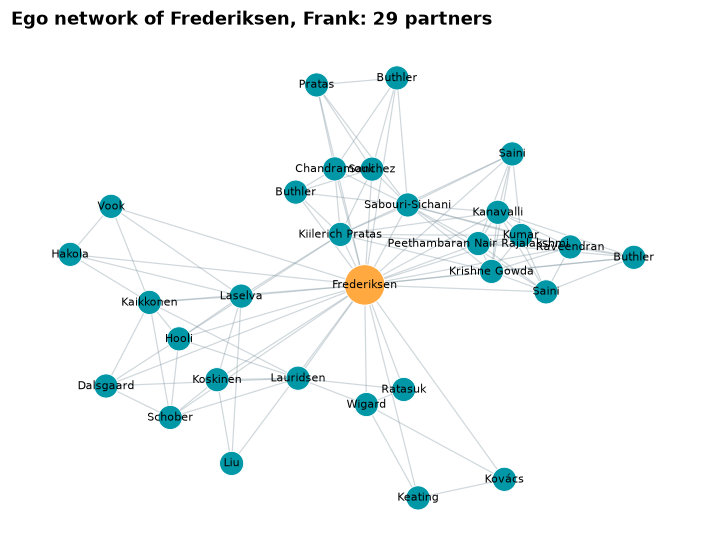

clustering of the ego network: 0.21 = share of his partners who also work with each other


In [ ]:
ego = nx.ego_graph(core, a, radius=1)
pe = nx.spring_layout(ego, seed=3)
draw(ego, pe, node_size=[700 if n == a else 250 for n in ego],
     node_color=[ORANGE if n == a else TEAL for n in ego],
     labels={n: n.split(",")[0].title() for n in ego}, font_size=7,
     title=f"Ego network of {a.title()}: {ego.number_of_nodes() - 1} partners")
plt.show()
print("clustering of the ego network:", round(nx.clustering(core, a), 2),
      "= share of his partners who also work with each other")

## 🧑‍💻 Your turn

1. Remove the inventor with the highest betweenness from the core. How many components do you get now?
   Do the same for the inventor with the highest *degree*. Which removal hurts more?
2. Compute **weighted** betweenness: `nx.betweenness_centrality(core, weight=...)`.
   Careful: for paths a *large* weight should mean a *short* distance, so first add `distance = 1 / weight`.

<details><summary>Solution to 1</summary>

```python
for who in [betweenness.idxmax(), degree.idxmax()]:
    H = core.copy(); H.remove_node(who)
    print(who, "->", nx.number_connected_components(H), "components")
```
</details>

In [ ]:
# your code here

## ✅ Key takeaways
- **Degree / strength**: breadth vs depth of collaboration.
- **Closeness**: how quickly you can reach everyone.
- **Betweenness**: brokers that hold the network together — often *not* the highest-degree nodes.
- **Eigenvector**: being connected to the well-connected.
- Always check a measure on a small example you can compute by hand.

**Next → Part 4:** from single inventors to the **whole network** and its **communities**.